# Predicting Movie Box Office Revenue

Real TMDB data this time: `ashen97/TMDB-box-office` on Hugging Face (CC BY-NC-SA 4.0), 9,999 movies pulled from the TMDB API with budget, revenue, genres, runtime, release date, cast and director. Many rows have budget or revenue recorded as 0 (TMDB's way of saying unknown), so I keep only films with a budget of at least $100K and revenue of at least $10K.

Features: log budget, runtime, release month, genres, and the director's track record. For the track record I only use films the same director released *earlier* in this dataset, so the model never sees a film's own revenue (or a later one) through that feature. I leave out vote counts and popularity because they're measured after release.

The shape of the problem is the interesting part: a heavy-tailed revenue distribution, log-target regression, genre dummies.

In [1]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

DATA = Path("../../data/box_office"); DATA.mkdir(parents=True, exist_ok=True)

## Load the TMDB films

In [2]:
CSV = DATA / "tmdb_box_office.csv"
if not CSV.exists():
    pd.read_csv("https://huggingface.co/datasets/ashen97/TMDB-box-office/resolve/main/tmdb%20dataset.csv").to_csv(CSV, index=False)
raw = pd.read_csv(CSV, parse_dates=["release_date"])
print("raw:", raw.shape)

df = raw[(raw["budget"] >= 1e5) & (raw["revenue"] >= 1e4) & raw["release_date"].notna() & (raw["runtime"] > 0)].copy()
df = df.sort_values("release_date").reset_index(drop=True)
df["release_month"] = df["release_date"].dt.month
df["genre_list"] = df["genres"].apply(lambda s: ast.literal_eval(s) if isinstance(s, str) else [])
df["log_revenue"] = np.log1p(df["revenue"])

# director track record: mean log revenue of the director's *earlier* films only
prior_mean = df.groupby("director")["log_revenue"].transform(lambda s: s.shift().expanding().mean())
df["has_director_history"] = prior_mean.notna().astype(int)
df["log_director_avg"] = prior_mean.fillna(df["log_revenue"].median())

print("films kept:", df.shape[0], " years:", df.release_date.dt.year.min(), "-", df.release_date.dt.year.max(),
      " with director history:", df["has_director_history"].sum())
df[["title", "budget", "revenue", "runtime", "release_date", "director"]].head()

raw: (9999, 15)
films kept: 4650  years: 1915 - 2025  with director history: 2636


,title,budget,revenue,runtime,release_date,director
0,The Birth of a Nation,100000,11000000,195,1915-02-08,D.W. Griffith
1,Intolerance: Love's Struggle Throughout the Ages,385907,1750000,197,1916-09-04,D.W. Griffith
2,The Kid,250000,2500000,68,1921-01-21,Charlie Chaplin
3,Safety Last!,121000,1500000,73,1923-04-01,Sam Taylor
4,The Gold Rush,923000,4000000,95,1925-07-13,Charlie Chaplin


## Skim — the target is wildly right-skewed, so I'll log it

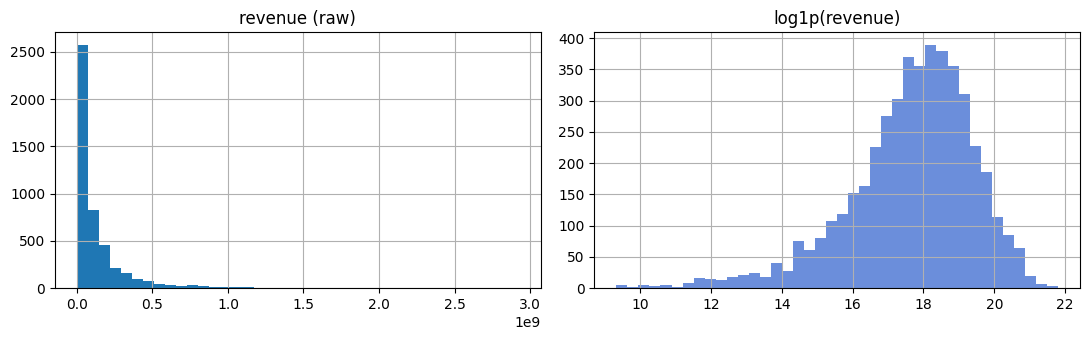

features: ['log_budget', 'runtime', 'release_month', 'log_director_avg', 'has_director_history', 'genre_drama', 'genre_comedy', 'genre_action', 'genre_thriller', 'genre_adventure', 'genre_crime', 'genre_romance', 'genre_science_fiction']


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["revenue"].hist(bins=40, ax=axes[0]); axes[0].set_title("revenue (raw)")
df["log_revenue"].hist(bins=40, ax=axes[1], color="#6b8edb"); axes[1].set_title("log1p(revenue)")
plt.tight_layout(); plt.show()

df["log_budget"] = np.log1p(df["budget"])

# multi-hot the 8 most common genres; keep release_month numeric
top_genres = pd.Series([g for gl in df["genre_list"] for g in gl]).value_counts().index[:8]
for g in top_genres:
    df["genre_" + g.lower().replace(" ", "_")] = df["genre_list"].apply(lambda gl: int(g in gl))
features = ["log_budget", "runtime", "release_month", "log_director_avg", "has_director_history"] + \
           [c for c in df.columns if c.startswith("genre_") and c != "genre_list"]
X = df[features].values
y = df["log_revenue"].values
print("features:", features)

## Gradient boosting on log-revenue

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
gb = GradientBoostingRegressor(n_estimators=400, max_depth=4, learning_rate=0.05, random_state=42)
cv = KFold(n_splits=5, shuffle=True, random_state=42)
r2_cv = cross_val_score(gb, X_tr, y_tr, cv=cv, scoring="r2")
mae_cv = -cross_val_score(gb, X_tr, y_tr, cv=cv, scoring="neg_mean_absolute_error")
print(f"5-fold CV  R2 mean={r2_cv.mean():.3f}  MAE(log) mean={mae_cv.mean():.3f}")

gb.fit(X_tr, y_tr)
pred_log = gb.predict(X_te)
print(f"test R2 (log space): {r2_score(y_te, pred_log):.3f}")
print(f"test MAE (log space): {mean_absolute_error(y_te, pred_log):.3f}")

# back to dollar space
pred_dollar = np.expm1(pred_log)
true_dollar = np.expm1(y_te)
print(f"test MAE (dollars): ${mean_absolute_error(true_dollar, pred_dollar):,.0f}")

5-fold CV  R2 mean=0.414  MAE(log) mean=0.981


test R2 (log space): 0.429
test MAE (log space): 0.972
test MAE (dollars): $75,891,960


## Feature importance

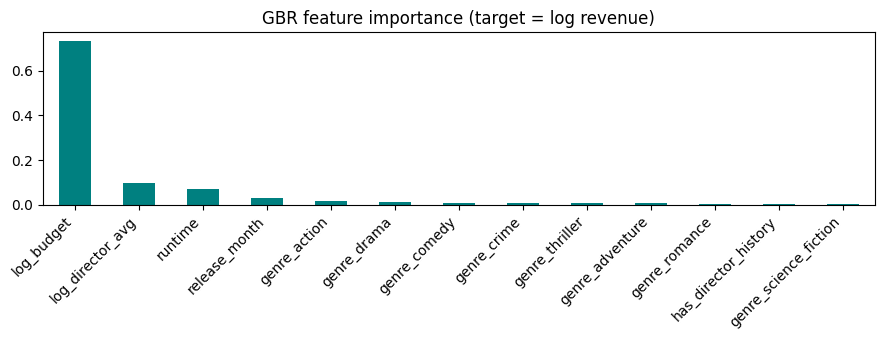

log_budget               0.735
log_director_avg         0.096
runtime                  0.068
release_month            0.029
genre_action             0.015
genre_drama              0.011
genre_comedy             0.009
genre_crime              0.007
genre_thriller           0.007
genre_adventure          0.007
genre_romance            0.006
has_director_history     0.005
genre_science_fiction    0.005


In [5]:
imp = pd.Series(gb.feature_importances_, index=features).sort_values(ascending=False)
imp.plot(kind="bar", figsize=(9, 3.5), color="teal")
plt.title("GBR feature importance (target = log revenue)")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()
print(imp.round(3).to_string())

## Honest reading

On 4,650 real films, gradient boosting explains about 41-43% of the variance in log revenue (5-fold CV R2 0.414, test R2 0.429). The typical error is large: a log-space MAE of 0.97 means the prediction is off by a factor of about 2.6 for a typical film, and the dollar MAE ($76M) is dominated by a few huge hits. That's in line with how hard box office is to call from pre-release metadata.

Budget does most of the work (0.74 of the importance). The director's earlier track record is a distant second (0.10), then runtime and release month. Genres barely register once budget is known, which makes sense: budget already encodes a lot of what genre would tell you (big action and sci-fi films get big budgets).

Things this version gets wrong or leaves out:
- Revenue and budget are nominal dollars across a century of films (1915 to 2025). Adjusting for inflation, or limiting to recent decades, would make the target more comparable.
- TMDB's revenue field mixes sources and isn't always worldwide gross, and the 0-as-unknown rows I dropped are probably not missing at random (small films are less likely to have numbers).
- Cast star power (the standard trick is the average of the top 3 billed actors' prior films), marketing spend, and release-window competition are all missing.
- A separate model for opening weekend vs total revenue. Different signals matter.

Log-target regression is the right move here regardless of dataset: revenue spans orders of magnitude and the optimization is much better behaved in log space.